In [196]:

# 📚 Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier


sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)


In [197]:
# data ingestion
climate_features = pd.read_csv("climate_features.csv")
test_data = pd.read_csv("Test.csv")
train_data = pd.read_csv("Train.csv")

# # data preprocessing
# # Drop rows with missing target values
# train_data = train_data.dropna(subset=[""])

# # Drop rows with missing climate features
# train_data = train_data.dropna(subset=climate_features.columns)

display(train_data.sample(5))


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive
1770,ID_DAA90AF9,Peri_urban,Male,2014-03-23,11.0,23.260891,27.766589,19.125875,1.825480,0.605119,33.475691,"Kasokoso South, Iganga, Uganda",1
2682,ID_6578EB1A,Rural,Female,2020-04-13,0.0,21.618105,24.846799,19.669237,3.690416,0.591526,33.509251,"Nakigo Ii, Iganga, Uganda",1
2625,ID_6D7BAE04,Rural,Male,2019-12-20,45.0,21.942158,27.246254,15.618000,0.000329,0.564485,33.506686,"Namirali, Iganga, Uganda",0
3006,ID_183E7864,Rural,Male,2021-08-07,1.0,21.844528,26.769877,17.589029,0.398142,0.547201,33.488916,"Nawanzu, Iganga, Uganda",1
2405,ID_9DEFD9C8,Peri_urban,Male,2018-05-10,52.0,21.484149,24.993275,18.962831,1.520661,0.603534,33.474301,"Buligo North, Iganga, Uganda",0


In [198]:
train_data.info()
train_data.describe()
# EDA

# drop id
train_data = train_data.drop(columns=["ID"])

# drop duplicates
train_data = train_data.drop_duplicates()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   object 
 1   zone                  3146 non-null   object 
 2   gender                3146 non-null   object 
 3   deathdate             3146 non-null   object 
 4   age                   3146 non-null   float64
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   object 
 12  is_climate_sensitive  3146 non-null   int64  
dtypes: float64(7), int64(1), object(5)
memory usage: 319.6+ KB


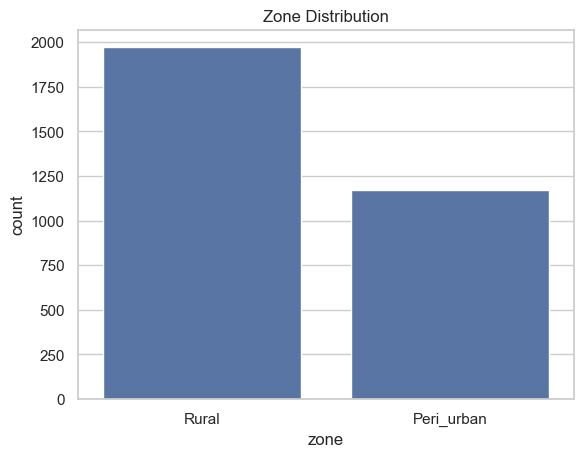

In [199]:
# EDA
# train_data Analysis -- CATEGORICAL DATA
train_data['zone'].value_counts()
sns.countplot(x='zone', data=train_data)
plt.title('Zone Distribution')
plt.show()

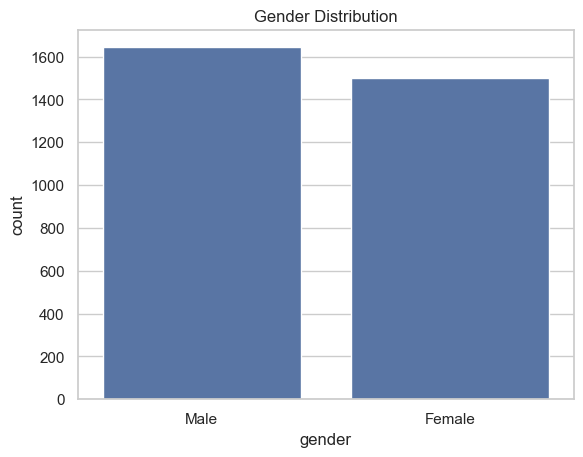

In [200]:
train_data['gender'].value_counts()
sns.countplot(x='gender', data=train_data)
plt.title('Gender Distribution')
plt.show()

In [201]:
# Find locations that appear more than once in the dataset
duplicate_locations = train_data[train_data.duplicated(subset=['location'], keep=False)]

location_counts = train_data['location'].value_counts()
duplicated_location_counts = location_counts[location_counts > 1].sort_index()

# convert Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda to Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Proper, Kasokoso North, Iganga, Uganda
train_data['location'] = train_data['location'].str.replace('Eastern Region', '')


# Normalize the "Brac Uganda Iganga..." location text so both variants merge
# into one consistent value (fix the "Propeer" typo, drop the stray
# ", Eastern Region" segment, and collapse any leftover double commas/spaces)
train_data['location'] = (
    train_data['location']
    .str.replace('Propeer', 'Proper', regex=False)
    .str.replace('Buwoya', 'Buwaya', regex=False)
    .str.replace(', Eastern Region', '', regex=False)
    .str.replace(r',\s*,', ',', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
    .str.replace(r'\s*,\s*', ', ', regex=True)
    .str.title()
    
)


duplicated_location_counts

location
Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda       210
Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda                       207
Budhwege, Iganga, Uganda                                                                                                80
Bukoyo, Iganga, Uganda                                                                                                  31
Bukwaya, Iganga, Uganda                                                                                                 79
Buligo North, Iganga, Uganda                                                                                            81
Buligo South, Iganga, Uganda                                                                                            97
Bulubandi Central B, Iganga, Uganda                                                                                      9
Bulumwa

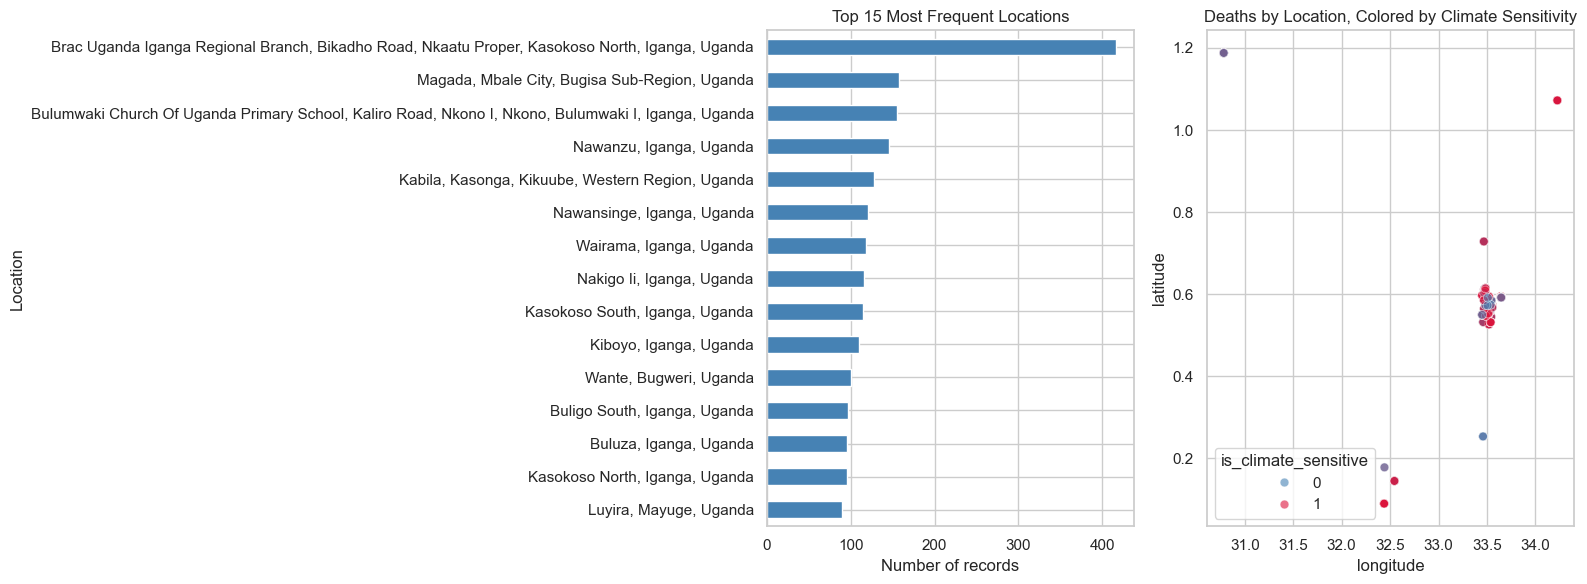

In [202]:
# location is high-cardinality free text (near-unique addresses), so a full
# categorical bar plot isn't readable. Instead: top-N most frequent locations,
# and a geospatial scatter (lat/long) colored by target, which is far more
# informative for a location field than plotting raw address strings.
top_locations = train_data['location'].value_counts().head(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_locations.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Top 15 Most Frequent Locations')
axes[0].set_xlabel('Number of records')
axes[0].set_ylabel('Location')

sns.scatterplot(
    data=train_data,
    x='longitude',
    y='latitude',
    hue='is_climate_sensitive',
    palette={0: 'steelblue', 1: 'crimson'},
    alpha=0.6,
    s=40,
    ax=axes[1],
)
axes[1].set_title('Deaths by Location, Colored by Climate Sensitivity')

plt.tight_layout()
plt.show()

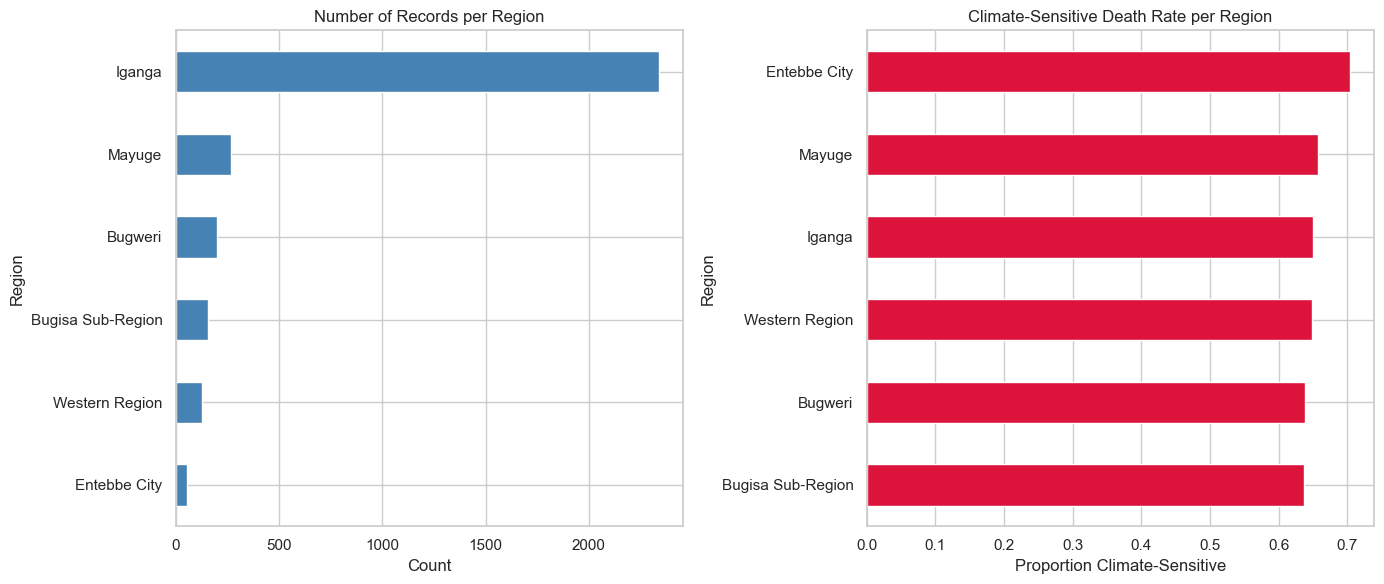

In [203]:
# Extract region: the segment right before ", Uganda" in the location string
train_data['region'] = train_data['location'].str.split(',').str[-2].str.strip()

train_data['region'].value_counts()

# region is proper low-cardinality categorical now, so a count + target-rate
# bar chart works well (unlike raw location)
region_counts = train_data['region'].value_counts().sort_values()
region_rate = train_data.groupby('region')['is_climate_sensitive'].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

region_counts.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Number of Records per Region')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Region')

region_rate.plot(kind='barh', ax=axes[1], color='crimson')
axes[1].set_title('Climate-Sensitive Death Rate per Region')
axes[1].set_xlabel('Proportion Climate-Sensitive')
axes[1].set_ylabel('Region')

plt.tight_layout()
plt.show()

In [204]:
# Death Date

# Group region, death_date, and is_climate_sensitive to get counts of
# climate-sensitive deaths per region per year
train_data['deathdate'] = pd.to_datetime(train_data['deathdate'])
train_data['death_year'] = train_data['deathdate'].dt.year

region_year_counts = (
    train_data
    .groupby(['region', 'death_year', 'is_climate_sensitive'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
)

region_year_counts

,region,death_year,is_climate_sensitive,count
85,Iganga,2009,1,257
87,Iganga,2010,1,194
89,Iganga,2011,1,146
91,Iganga,2012,1,122
93,Iganga,2013,1,120
...,...,...,...,...
80,Entebbe City,2021,1,1
81,Iganga,2007,1,1
141,Western Region,2008,0,1
130,Mayuge,2017,0,1


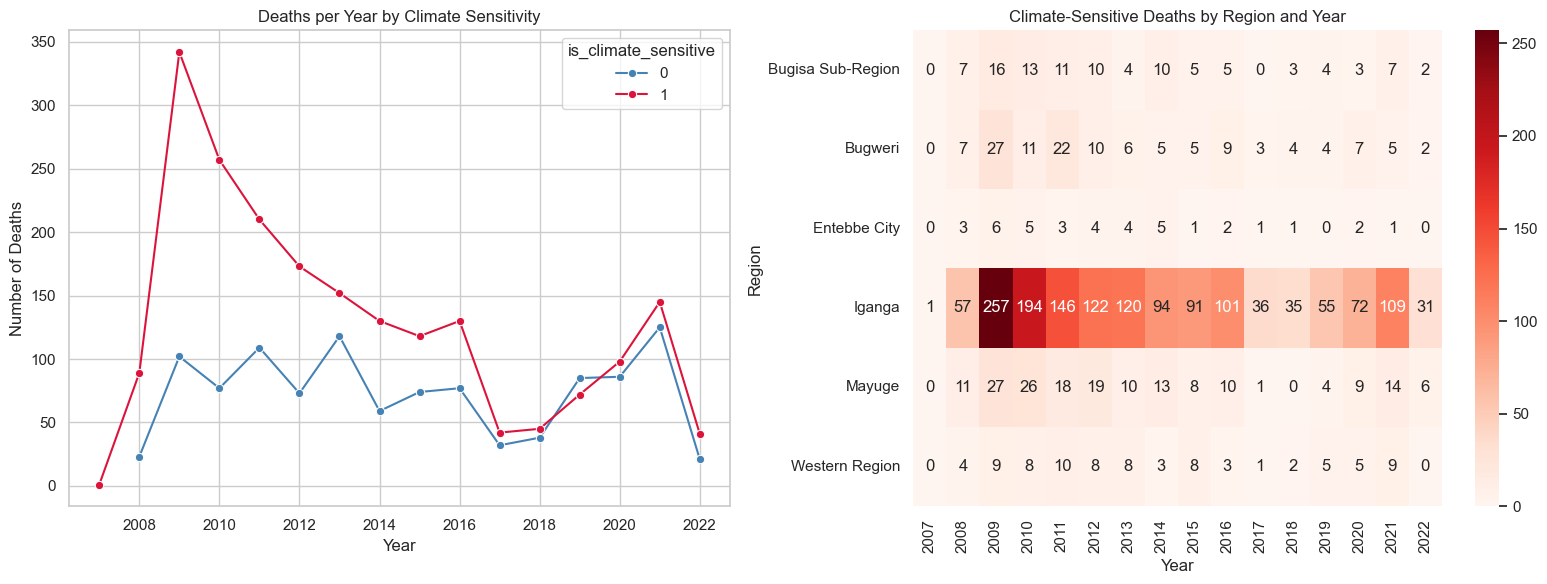

In [205]:
# Visualize: overall yearly trend of climate-sensitive vs other deaths, and
# a region x year heatmap of climate-sensitive death counts
yearly_counts = (
    train_data
    .groupby(['death_year', 'is_climate_sensitive'])
    .size()
    .reset_index(name='count')
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.lineplot(
    data=yearly_counts,
    x='death_year',
    y='count',
    hue='is_climate_sensitive',
    marker='o',
    palette={0: 'steelblue', 1: 'crimson'},
    ax=axes[0],
)
axes[0].set_title('Deaths per Year by Climate Sensitivity')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Deaths')

climate_sensitive_pivot = (
    region_year_counts[region_year_counts['is_climate_sensitive'] == 1]
    .pivot(index='region', columns='death_year', values='count')
    .fillna(0)
)

sns.heatmap(climate_sensitive_pivot, cmap='Reds', annot=True, fmt='.0f', ax=axes[1])
axes[1].set_title('Climate-Sensitive Deaths by Region and Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Region')

plt.tight_layout()
plt.show()

,climate_sensitive_deaths,total_deaths,climate_sensitive_rate
age_group,,,
0-4,1447,1731,0.835933
5-17,87,139,0.625899
18-39,177,339,0.522124
40-59,140,289,0.484429
60+,194,646,0.300310


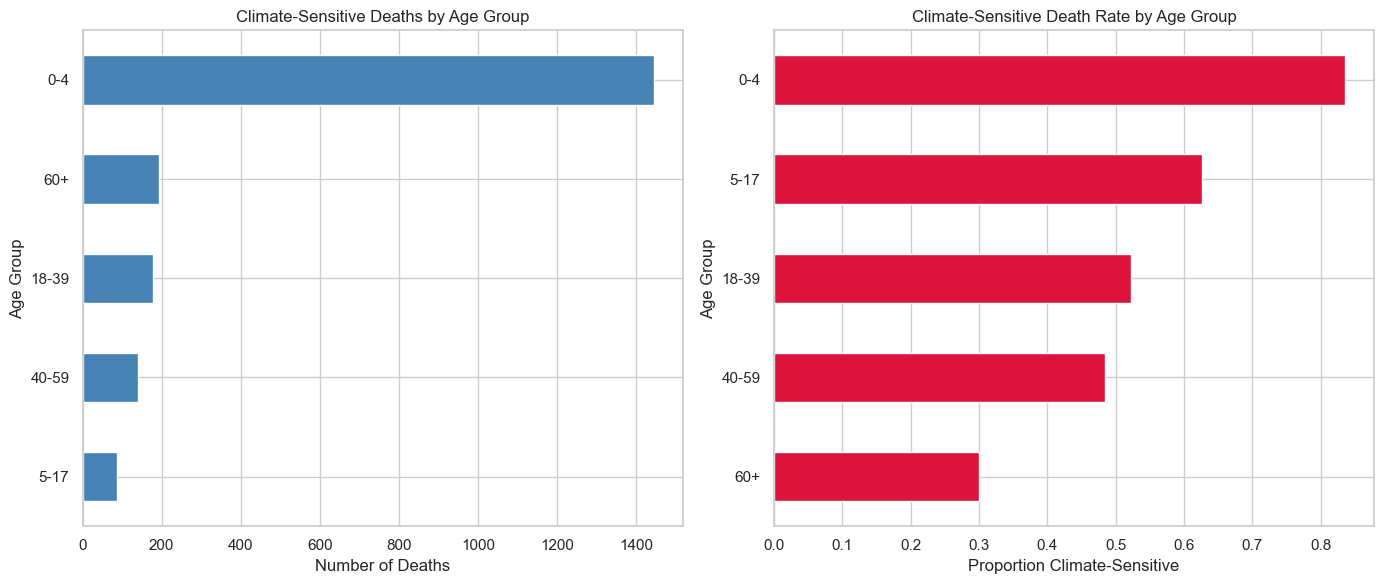

In [206]:
# Age groups most affected by climate-sensitive deaths
age_bins = [-1, 4, 17, 39, 59, np.inf]
age_labels = ["0-4", "5-17", "18-39", "40-59", "60+"]
age_group_for_analysis = pd.cut(train_data['age'], bins=age_bins, labels=age_labels)

age_group_stats = (
    train_data
    .assign(age_group=age_group_for_analysis)
    .groupby('age_group', observed=True)['is_climate_sensitive']
    .agg(climate_sensitive_deaths='sum', total_deaths='count', climate_sensitive_rate='mean')
    .sort_values('climate_sensitive_rate', ascending=False)
)

display(age_group_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

age_group_stats['climate_sensitive_deaths'].sort_values().plot(
    kind='barh', ax=axes[0], color='steelblue'
)
axes[0].set_title('Climate-Sensitive Deaths by Age Group')
axes[0].set_xlabel('Number of Deaths')
axes[0].set_ylabel('Age Group')

age_group_stats['climate_sensitive_rate'].sort_values().plot(
    kind='barh', ax=axes[1], color='crimson'
)
axes[1].set_title('Climate-Sensitive Death Rate by Age Group')
axes[1].set_xlabel('Proportion Climate-Sensitive')
axes[1].set_ylabel('Age Group')

plt.tight_layout()
plt.show()

In [207]:
# perform encoding on the categorical variables
# One-hot encode gender, zone, and region using sklearn's OneHotEncoder.
# location is excluded (too high-cardinality/free-text for one-hot), and
# deathdate is dropped since death_year already captures its year signal
categorical_cols = ['gender', 'zone', 'region']

encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
encoded_array = encoder.fit_transform(train_data[categorical_cols])
encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=train_data.index,
)

train_data = pd.concat([train_data.drop(columns=categorical_cols), encoded_df], axis=1)
train_data = train_data.drop(columns=['location', 'deathdate'])

train_data.sample(5)

,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,is_climate_sensitive,death_year,gender_Male,zone_Rural,region_Bugweri,region_Entebbe City,region_Iganga,region_Mayuge,region_Western Region
274,2.0,20.819737,23.823357,18.503145,2.619553,0.608512,33.475521,1,2009,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1430,32.0,22.848853,26.987074,18.976336,1.415440,0.608396,33.482668,1,2012,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1737,0.0,22.314087,26.415409,19.797585,1.386114,0.526398,33.519818,1,2014,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1246,1.0,22.745821,25.551658,20.535698,4.646337,0.615049,33.485670,1,2012,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2449,26.0,21.764210,26.082695,18.715646,2.633223,0.607620,33.483891,1,2018,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [208]:

# Split the data into features and target variable
X = train_data.drop(columns=["is_climate_sensitive"]) 
y = train_data["is_climate_sensitive"] 


print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (3144, 15)
Target shape: (3144,)


In [209]:
# Logistic Regression baseline (kept simple: no Pipeline/ColumnTransformer)
# Split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

F1-score:        0.7804
ROC-AUC:          0.8044
Combined (60/40): 0.7900

              precision    recall  f1-score   support

           0       0.59      0.71      0.65       220
           1       0.83      0.74      0.78       409

    accuracy                           0.73       629
   macro avg       0.71      0.73      0.71       629
weighted avg       0.75      0.73      0.73       629



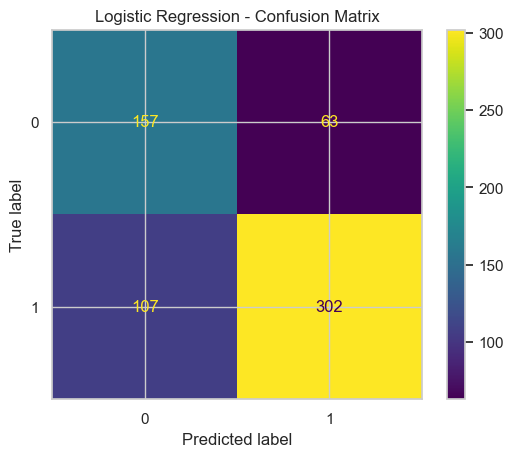

In [210]:


# Scale the numeric/continuous features (LR is scale-sensitive); the
# one-hot dummy columns are already 0/1 so they're left as-is
numeric_features = [
    'age', 'avg_temperature', 'max_temperature', 'min_temperature',
    'precipitation', 'latitude', 'longitude', 'death_year',
]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_val_scaled[numeric_features] = scaler.transform(X_val[numeric_features])

model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Binary prediction at the default 0.5 threshold + predicted probability
y_val_pred = model.predict(X_val_scaled)
y_val_proba = model.predict_proba(X_val_scaled)[:, 1]

f1 = f1_score(y_val, y_val_pred)
auc = roc_auc_score(y_val, y_val_proba)
combined_score = 0.6 * f1 + 0.4 * auc

print(f"F1-score:        {f1:.4f}")
print(f"ROC-AUC:          {auc:.4f}")
print(f"Combined (60/40): {combined_score:.4f}")
print()
print(classification_report(y_val, y_val_pred))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred)
plt.title('Logistic Regression - Confusion Matrix')
plt.show()


F1-score:        0.7835
ROC-AUC:          0.7978
Combined (60/40): 0.7893

              precision    recall  f1-score   support

           0       0.60      0.51      0.55       220
           1       0.76      0.81      0.78       409

    accuracy                           0.71       629
   macro avg       0.68      0.66      0.67       629
weighted avg       0.70      0.71      0.70       629



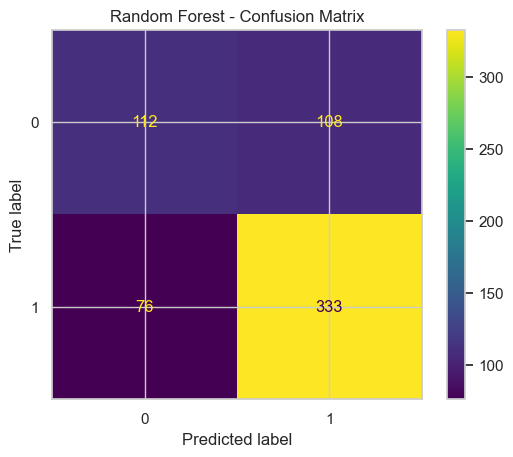

In [211]:
# Random Forest (no scaling needed - trees are scale-invariant)
rf_model = RandomForestClassifier(
    n_estimators=300, class_weight='balanced', random_state=42
)
rf_model.fit(X_train, y_train)

# Binary prediction at the default 0.5 threshold + predicted probability
y_val_pred_rf = rf_model.predict(X_val)
y_val_proba_rf = rf_model.predict_proba(X_val)[:, 1]

f1_rf = f1_score(y_val, y_val_pred_rf)
auc_rf = roc_auc_score(y_val, y_val_proba_rf)
combined_score_rf = 0.6 * f1_rf + 0.4 * auc_rf

print(f"F1-score:        {f1_rf:.4f}")
print(f"ROC-AUC:          {auc_rf:.4f}")
print(f"Combined (60/40): {combined_score_rf:.4f}")
print()
print(classification_report(y_val, y_val_pred_rf))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred_rf)
plt.title('Random Forest - Confusion Matrix')
plt.show()

In [212]:
# LightGBM (no scaling needed - trees are scale-invariant)
lgbm_model = LGBMClassifier(
    n_estimators=300, class_weight='balanced', random_state=42, verbose=-1
)
lgbm_model.fit(X_train, y_train)

# Binary prediction at the default 0.5 threshold + predicted probability
y_val_pred_lgbm = lgbm_model.predict(X_val)
y_val_proba_lgbm = lgbm_model.predict_proba(X_val)[:, 1]

f1_lgbm = f1_score(y_val, y_val_pred_lgbm)
auc_lgbm = roc_auc_score(y_val, y_val_proba_lgbm)
combined_score_lgbm = 0.6 * f1_lgbm + 0.4 * auc_lgbm

print(f"F1-score:        {f1_lgbm:.4f}")
print(f"ROC-AUC:          {auc_lgbm:.4f}")
print(f"Combined (60/40): {combined_score_lgbm:.4f}")
print()
print(classification_report(y_val, y_val_pred_lgbm))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred_lgbm)
plt.title('LightGBM - Confusion Matrix')
plt.show()

OSError: exception: access violation reading 0x0000000000000000

In [ ]:

# XGBoost (no scaling needed - trees are scale-invariant)
# XGBoost has no class_weight param, so imbalance is handled via
# scale_pos_weight = negative_count / positive_count
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=300,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
)
xgb_model.fit(X_train, y_train)

# Binary prediction at the default 0.5 threshold + predicted probability
y_val_pred_xgb = xgb_model.predict(X_val)
y_val_proba_xgb = xgb_model.predict_proba(X_val)[:, 1]

f1_xgb = f1_score(y_val, y_val_pred_xgb)
auc_xgb = roc_auc_score(y_val, y_val_proba_xgb)
combined_score_xgb = 0.6 * f1_xgb + 0.4 * auc_xgb

print(f"F1-score:        {f1_xgb:.4f}")
print(f"ROC-AUC:          {auc_xgb:.4f}")
print(f"Combined (60/40): {combined_score_xgb:.4f}")
print()
print(classification_report(y_val, y_val_pred_xgb))

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred_xgb)
plt.title('XGBoost - Confusion Matrix')
plt.show()